# JS11 – Klasifikasi 2: Tugas Praktikum
## SVM pada Data Suara dan Klasifikasi Citra Siang/Malam

**Tujuan tugas**

1. Membandingkan kernel **linear**, **polynomial**, dan **RBF** pada dataset `voice.csv` untuk rasio split 70:30 dan 80:20.
2. Menabulasikan performa setiap kernel dan split berdasarkan akurasi.
3. Membangun classifier siang/malam dengan SVM kernel RBF menggunakan **fitur histogram**.
4. Melakukan hyperparameter tuning pada kernel RBF.
5. Membandingkan performa fitur histogram dengan fitur rata-rata kecerahan sederhana.

**Data yang digunakan**

- `voice.csv`: 3.168 sampel suara, 20 fitur akustik, label `male`/`female` (seimbang 1.584 : 1.584).
- `images/`: 400 citra siang dan malam (240 training + 160 test pada folder asli). Pada bagian B, seluruh 400 citra digabung lalu dibagi 80:20.

### 0. Import library

In [1]:
import platform
import time
from pathlib import Path

import cv2
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 50)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("OpenCV  :", cv2.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
OpenCV  : 5.0.0
seaborn : 0.13.2


# Bagian A — Klasifikasi Suara dengan Berbagai Kernel SVM

## A.1 Memuat dan memeriksa data

In [2]:
voice = pd.read_csv("voice.csv")

print("Ukuran data:", voice.shape)
print("\nDistribusi label:")
print(voice["label"].value_counts())
print("\nProporsi (%):")
print((voice["label"].value_counts(normalize=True) * 100).round(2))
voice.head()

Ukuran data: (3168, 21)

Distribusi label:
label
male      1584
female    1584
Name: count, dtype: int64

Proporsi (%):
label
male      50.0
female    50.0
Name: proportion, dtype: float64


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,0.000000,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,0.000000,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,0.000000,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,0.083878,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,0.104261,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [3]:
print("Jumlah nilai kosong:", voice.isna().sum().sum())
print("Jumlah baris duplikat:", voice.duplicated().sum())
voice.describe().T

Jumlah nilai kosong: 0
Jumlah baris duplikat: 2


,count,mean,std,min,25%,50%,75%,max
meanfreq,3168.0,0.180907,0.029918,0.039363,0.163662,0.184838,0.199146,0.251124
sd,3168.0,0.057126,0.016652,0.018363,0.041954,0.059155,0.067020,0.115273
median,3168.0,0.185621,0.036360,0.010975,0.169593,0.190032,0.210618,0.261224
Q25,3168.0,0.140456,0.048680,0.000229,0.111087,0.140286,0.175939,0.247347
Q75,3168.0,0.224765,0.023639,0.042946,0.208747,0.225684,0.243660,0.273469
IQR,3168.0,0.084309,0.042783,0.014558,0.042560,0.094280,0.114175,0.252225
skew,3168.0,3.140168,4.240529,0.141735,1.649569,2.197101,2.931694,34.725453
kurt,3168.0,36.568461,134.928661,2.068455,5.669547,8.318463,13.648905,1309.612887
sp.ent,3168.0,0.895127,0.044980,0.738651,0.861811,0.901767,0.928713,0.981997
sfm,3168.0,0.408216,0.177521,0.036876,0.258041,0.396335,0.533676,0.842936


Dataset memiliki 20 fitur numerik dengan skala yang sangat berbeda. Misalnya, `meanfreq` berada di sekitar 0–0,3, sedangkan `kurt` dan `dfrange` dapat bernilai puluhan hingga ratusan. Karena SVM berbasis jarak, **standardisasi** sangat penting. Tanpa scaling, fitur dengan rentang besar akan mendominasi perhitungan kernel.

## A.2 Fungsi evaluasi

In [4]:
def evaluate_svm(kernel, test_size, scaled=True):
    X = voice.drop(columns="label")
    y = voice["label"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y,
    )

    if scaled:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("svc", SVC(kernel=kernel, C=1.0, gamma="scale")),
        ])
    else:
        model = SVC(kernel=kernel, C=1.0, gamma="scale")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    return {
        "Split": f"{int((1 - test_size) * 100)}:{int(test_size * 100)}",
        "Kernel": kernel,
        "Scaled": "Ya" if scaled else "Tidak",
        "Akurasi latih": accuracy_score(y_train, model.predict(X_train)),
        "Akurasi test": accuracy_score(y_test, y_pred),
        "Precision male": precision_score(y_test, y_pred, pos_label="male"),
        "Recall male": recall_score(y_test, y_pred, pos_label="male"),
        "F1 male": f1_score(y_test, y_pred, pos_label="male"),
    }, (y_test, y_pred)

## A.3 Perbandingan kernel pada split 70:30 dan 80:20

Semua model menggunakan `C=1.0` dan `gamma='scale'` agar perbandingan fokus pada jenis kernel. Standardisasi dilakukan di dalam pipeline untuk mencegah data leakage.

In [5]:
hasil_a = []
prediksi_rbf = {}

for test_size in [0.3, 0.2]:
    for kernel in ["linear", "poly", "rbf"]:
        row, pred = evaluate_svm(kernel, test_size, scaled=True)
        hasil_a.append(row)
        if kernel == "rbf":
            prediksi_rbf[row["Split"]] = pred

hasil_a = pd.DataFrame(hasil_a)
hasil_a.round(4)

,Split,Kernel,Scaled,Akurasi latih,Akurasi test,Precision male,Recall male,F1 male
0,70:30,linear,Ya,0.9720,0.9790,0.9730,0.9853,0.9791
1,70:30,poly,Ya,0.9666,0.9600,0.9344,0.9895,0.9611
2,70:30,rbf,Ya,0.9838,0.9832,0.9811,0.9853,0.9832
3,80:20,linear,Ya,0.9767,0.9748,0.9659,0.9842,0.9750
4,80:20,poly,Ya,0.9680,0.9558,0.9263,0.9905,0.9573
5,80:20,rbf,Ya,0.9838,0.9826,0.9781,0.9874,0.9827


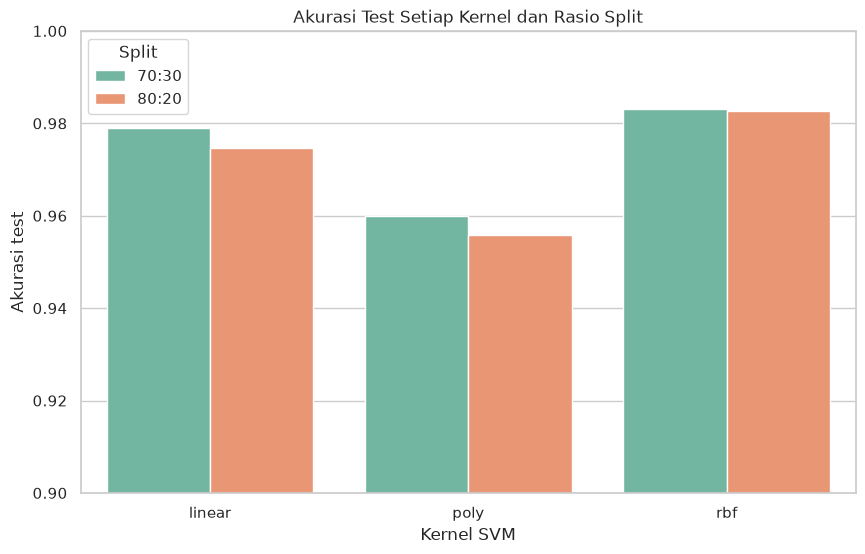

In [6]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=hasil_a,
    x="Kernel",
    y="Akurasi test",
    hue="Split",
    palette="Set2",
)
plt.title("Akurasi Test Setiap Kernel dan Rasio Split")
plt.xlabel("Kernel SVM")
plt.ylabel("Akurasi test")
plt.ylim(0.90, 1.0)
plt.legend(title="Split")
plt.show()

**Tabel performa**

| Split | Kernel | Akurasi latih | Akurasi test | Precision male | Recall male | F1 male |
|---|---|---:|---:|---:|---:|---:|
| 70:30 | Linear | 0,9720 | 0,9790 | 0,9730 | 0,9853 | 0,9791 |
| 70:30 | Polynomial | 0,9666 | 0,9600 | 0,9344 | 0,9895 | 0,9611 |
| 70:30 | RBF | 0,9838 | **0,9832** | 0,9811 | 0,9853 | 0,9832 |
| 80:20 | Linear | 0,9767 | 0,9748 | 0,9659 | 0,9842 | 0,9750 |
| 80:20 | Polynomial | 0,9680 | 0,9558 | 0,9263 | 0,9905 | 0,9573 |
| 80:20 | RBF | 0,9838 | **0,9826** | 0,9781 | 0,9874 | 0,9827 |

**Analisis**

- **RBF konsisten terbaik** pada kedua split: 98,32% (70:30) dan 98,26% (80:20).
- **Linear** sangat kompetitif: 97,90% dan 97,48%. Ini menunjukkan bahwa fitur suara hampir dapat dipisahkan secara linear setelah standardisasi.
- **Polynomial** paling rendah: 96,00% dan 95,58%. Dengan parameter default (`degree=3`, `C=1`), kernel polynomial lebih sulit menyesuaikan data dibanding RBF dan linear. Hasil ini bisa berubah jika degree, `coef0`, dan `C` dituning.
- Perbedaan 70:30 dan 80:20 kecil; RBF hanya turun 0,06 poin persentase ketika data latih diperbanyak dan data uji diperkecil.

## A.4 Confusion matrix kernel RBF

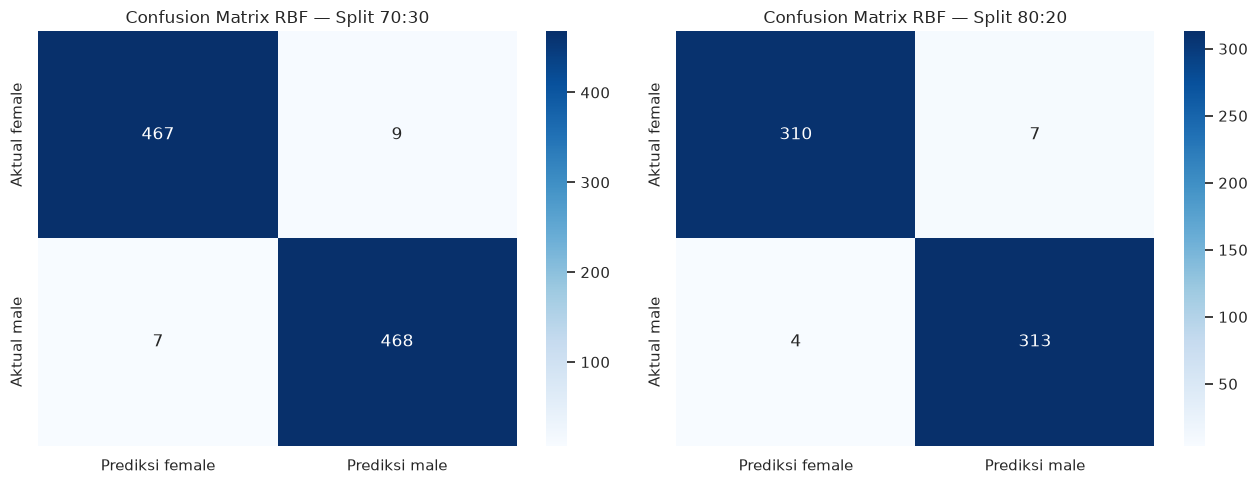

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, split in zip(axes, ["70:30", "80:20"]):
    y_true, y_pred = prediksi_rbf[split]
    cm = confusion_matrix(y_true, y_pred, labels=["female", "male"])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Prediksi female", "Prediksi male"],
        yticklabels=["Aktual female", "Aktual male"],
        ax=ax,
    )
    ax.set_title(f"Confusion Matrix RBF — Split {split}")

plt.tight_layout()
plt.show()

## A.5 Pentingnya standardisasi

Kita bandingkan performa SVM tanpa dan dengan `StandardScaler` pada kedua rasio split.

In [8]:
hasil_scaling = []

for test_size in [0.3, 0.2]:
    for kernel in ["linear", "poly", "rbf"]:
        for scaled in [False, True]:
            row, _ = evaluate_svm(kernel, test_size, scaled=scaled)
            hasil_scaling.append(row)

hasil_scaling = pd.DataFrame(hasil_scaling)
pivot_scaling = hasil_scaling.pivot_table(
    index=["Split", "Kernel"],
    columns="Scaled",
    values="Akurasi test",
).reset_index()
pivot_scaling.columns.name = None
pivot_scaling.rename(columns={"Tidak": "Tanpa scaling", "Ya": "Dengan scaling"}).round(4)

,Split,Kernel,Tanpa scaling,Dengan scaling
0,70:30,linear,0.9201,0.9790
1,70:30,poly,0.5110,0.9600
2,70:30,rbf,0.6951,0.9832
3,80:20,linear,0.9180,0.9748
4,80:20,poly,0.5174,0.9558
5,80:20,rbf,0.6940,0.9826


**Pengaruh scaling**

- Tanpa scaling, RBF hanya mencapai sekitar **69,5%** (70:30) dan **69,4%** (80:20).
- Dengan scaling, RBF naik menjadi **98,32%** dan **98,26%**.
- Linear juga meningkat dari sekitar 92% menjadi 97–98%.
- Polynomial tanpa scaling sangat buruk (sekitar 51%), lalu naik ke 96% setelah scaling.

Ini menunjukkan bahwa klaim “SVM tahan terhadap skala fitur” tidak benar untuk praktik. Standardisasi adalah langkah wajib pada dataset dengan fitur berskala berbeda.

## A.6 Kesimpulan Bagian A

1. Kernel **RBF** memberikan akurasi test tertinggi pada kedua split: **98,32%** (70:30) dan **98,26%** (80:20).
2. Kernel **linear** hampir setara, menunjukkan data suara setelah scaling hampir linear-separable.
3. Kernel **polynomial** dengan parameter default paling rendah; tuning degree dan `C` dapat meningkatkan performanya.
4. Perbedaan performa antara split 70:30 dan 80:20 sangat kecil, sehingga model cukup stabil.
5. **Standardisasi fitur** meningkatkan akurasi secara drastis, terutama untuk RBF dan polynomial.

# Bagian B — Klasifikasi Siang/Malam dengan Fitur Histogram

## B.1 Memuat dataset citra

Seluruh 400 citra dari folder `training` dan `test` digabung, lalu dibagi ulang 80:20 dengan stratifikasi. Ini sesuai permintaan tugas dan memastikan pembagian yang konsisten.

In [9]:
def load_paths(img_dir):
    p = Path(img_dir)
    items = []
    for folder in sorted(p.iterdir()):
        if folder.is_dir():
            for file in sorted(folder.glob("*.jpg")):
                items.append((file, folder.name))
    return items


all_images = load_paths("images/training") + load_paths("images/test")

print("Total gambar:", len(all_images))
from collections import Counter
print(Counter(label for _, label in all_images))

Total gambar: 400
Counter({'day': 200, 'night': 200})


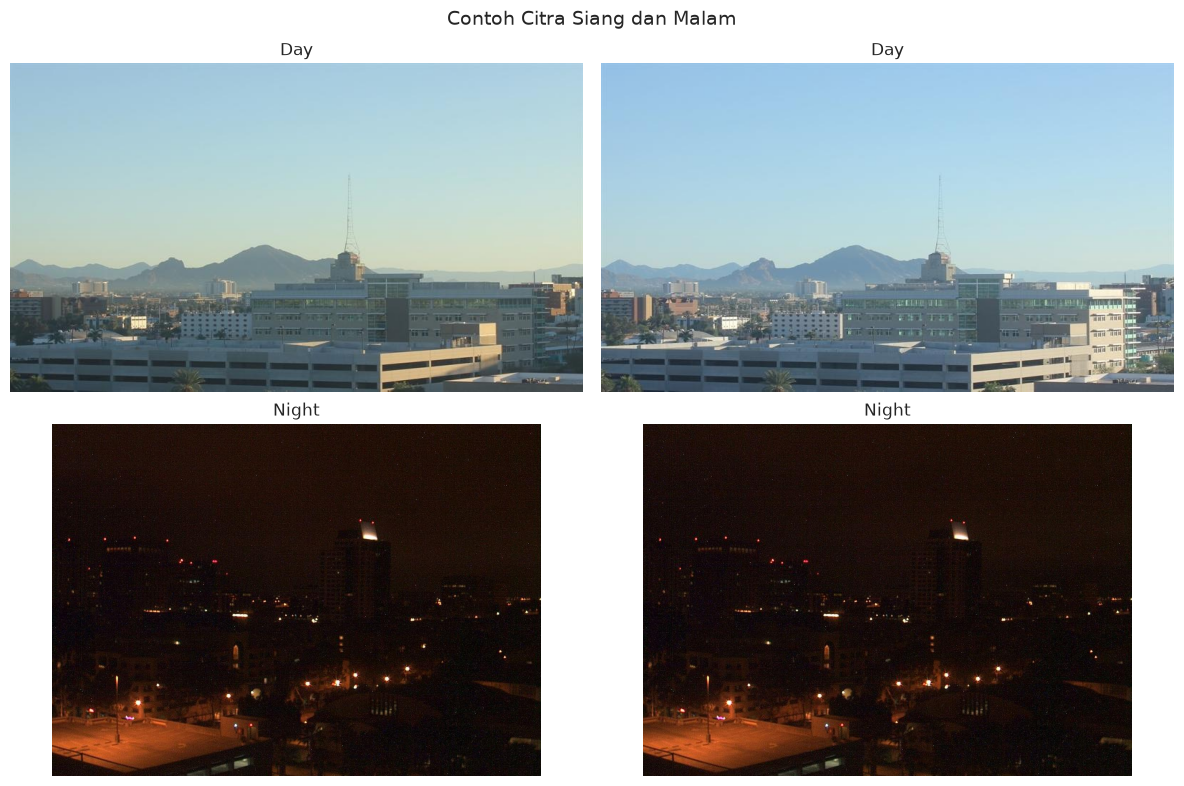

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

day_samples = [p for p, label in all_images if label == "day"][:2]
night_samples = [p for p, label in all_images if label == "night"][:2]

for ax, path in zip(axes[0], day_samples):
    img = mpimg.imread(path)
    ax.imshow(img)
    ax.set_title("Day")
    ax.axis("off")

for ax, path in zip(axes[1], night_samples):
    img = mpimg.imread(path)
    ax.imshow(img)
    ax.set_title("Night")
    ax.axis("off")

plt.suptitle("Contoh Citra Siang dan Malam", size=14)
plt.tight_layout()
plt.show()

## B.2 Ekstraksi fitur histogram

Setiap gambar distandarkan ke ukuran **1100 × 600**, diubah ke ruang warna HSV, lalu diambil histogram kanal **V (Value)** dengan 32 bin. Histogram dinormalisasi sehingga jumlah seluruh bin sama dengan 1.

Selain histogram, kita juga menyimpan rata-rata kecerahan sebagai pembanding.

In [11]:
def load_image(path, size=(1100, 600)):
    img = mpimg.imread(path)
    if img.ndim == 3 and img.shape[2] == 4:
        img = img[:, :, :3]
    if img.dtype != np.uint8:
        if img.max() <= 1.0:
            img = (img * 255).astype(np.uint8)
        else:
            img = img.astype(np.uint8)
    return cv2.resize(img, size)


def hist_v_from_image(img, bins=32):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist([hsv[:, :, 2]], [0], None, [bins], [0, 256]).ravel()
    return hist / (hist.sum() + 1e-12)


def brightness_from_image(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    return float(hsv[:, :, 2].mean())


rows = []
t0 = time.time()

for path, label in all_images:
    img = load_image(path)
    rows.append({
        "path": str(path),
        "label": label,
        "label_num": 1 if label == "day" else 0,
        "brightness": brightness_from_image(img),
        "hist_v": hist_v_from_image(img),
    })

df_img = pd.DataFrame(rows)
print(f"Ekstraksi selesai dalam {time.time() - t0:.1f} detik")
print("Bentuk data:", df_img.shape)
df_img[["label", "brightness"]].groupby("label").describe().round(2)

Ekstraksi selesai dalam 9.4 detik
Bentuk data: (400, 5)


brightness                                                      
           count    mean    std    min     25%     50%     75%     max
label                                                                 
day        200.0  138.78  27.07  93.14  116.22  132.70  156.38  201.61
night      200.0   65.59  37.19   8.11   26.80   73.69   98.71  176.83

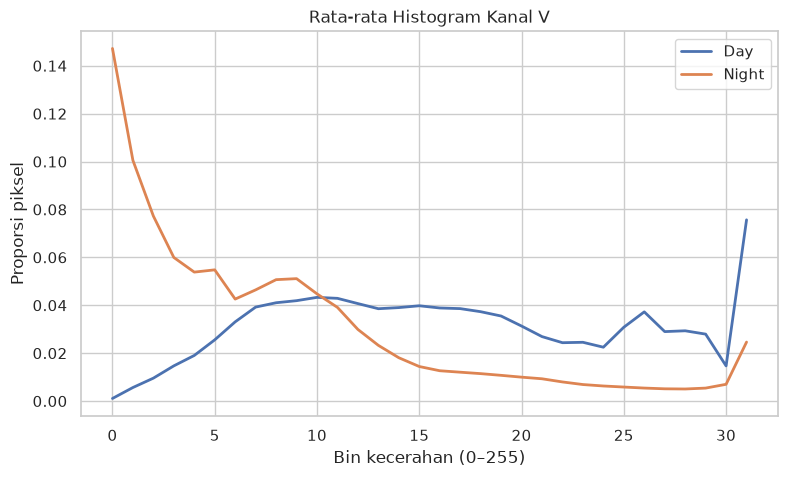

In [12]:
day_hist = np.mean(np.vstack(df_img[df_img.label == "day"]["hist_v"].values), axis=0)
night_hist = np.mean(np.vstack(df_img[df_img.label == "night"]["hist_v"].values), axis=0)

plt.figure(figsize=(9, 5))
plt.plot(day_hist, label="Day", linewidth=2)
plt.plot(night_hist, label="Night", linewidth=2)
plt.title("Rata-rata Histogram Kanal V")
plt.xlabel("Bin kecerahan (0–255)")
plt.ylabel("Proporsi piksel")
plt.legend()
plt.show()

Histogram siang bergeser ke kanan (nilai kecerahan tinggi), sedangkan histogram malam terkonsentrasi di kiri. Namun, keduanya memiliki area tumpang tindih, sehingga classifier tetap membutuhkan model yang baik.

## B.3 Pembagian data 80:20

In [13]:
X_hist = np.vstack(df_img["hist_v"].values)
X_bright = df_img[["brightness"]].values
y_img = df_img["label_num"].values

indices = np.arange(len(df_img))
idx_train, idx_test, y_train, y_test = train_test_split(
    indices,
    y_img,
    test_size=0.2,
    random_state=42,
    stratify=y_img,
)

print("Data latih:", len(idx_train), "| kelas:", np.bincount(y_train))
print("Data uji  :", len(idx_test), "| kelas:", np.bincount(y_test))

Data latih: 320 | kelas: [160 160]
Data uji  : 80 | kelas: [40 40]


## B.4 Hyperparameter tuning SVM RBF pada fitur histogram

GridSearchCV mencoba kombinasi `C` dan `gamma` dengan 5-fold stratified cross-validation. Pipeline standardisasi memastikan setiap fitur histogram memiliki skala yang setara.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def tune_rbf(X_train, y_train):
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf")),
    ])
    param_grid = {
        "svc__C": [0.1, 1, 10, 100],
        "svc__gamma": ["scale", 0.01, 0.1, 1],
    }
    grid = GridSearchCV(
        pipeline,
        param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    grid.fit(X_train, y_train)
    return grid


t0 = time.time()
grid_hist = tune_rbf(X_hist[idx_train], y_train)
print(f"Waktu tuning histogram: {time.time() - t0:.1f} detik")
print("Parameter terbaik:", grid_hist.best_params_)
print(f"CV accuracy terbaik: {grid_hist.best_score_:.4f}")

Waktu tuning histogram: 4.3 detik
Parameter terbaik: {'svc__C': 1, 'svc__gamma': 0.1}
CV accuracy terbaik: 0.9906


In [15]:
def evaluate_grid(grid, X_train, y_train, X_test, y_test):
    pred_train = grid.predict(X_train)
    pred_test = grid.predict(X_test)
    return {
        "Akurasi latih": accuracy_score(y_train, pred_train),
        "Akurasi test": accuracy_score(y_test, pred_test),
        "Precision day": precision_score(y_test, pred_test, pos_label=1),
        "Recall day": recall_score(y_test, pred_test, pos_label=1),
        "F1 day": f1_score(y_test, pred_test, pos_label=1),
    }, pred_test


metrik_hist, pred_hist = evaluate_grid(
    grid_hist,
    X_hist[idx_train],
    y_train,
    X_hist[idx_test],
    y_test,
)

print("Metrik histogram:")
for key, value in metrik_hist.items():
    print(f"- {key}: {value:.4f}")

print("\nLaporan Klasifikasi:")
print(classification_report(
    y_test,
    pred_hist,
    target_names=["night", "day"],
    digits=4,
))

Metrik histogram:
- Akurasi latih: 0.9938
- Akurasi test: 0.9875
- Precision day: 0.9756
- Recall day: 1.0000
- F1 day: 0.9877

Laporan Klasifikasi:
              precision    recall  f1-score   support

       night     1.0000    0.9750    0.9873        40
         day     0.9756    1.0000    0.9877        40

    accuracy                         0.9875        80
   macro avg     0.9878    0.9875    0.9875        80
weighted avg     0.9878    0.9875    0.9875        80



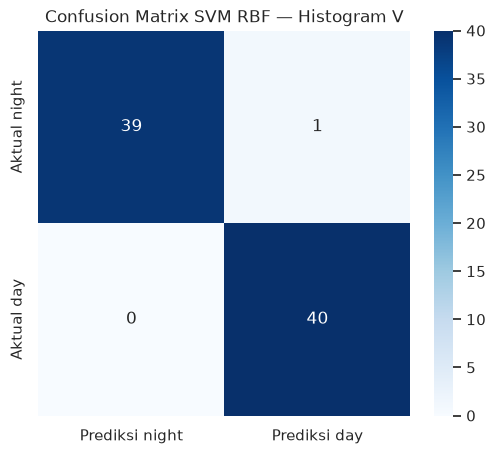

In [16]:
cm_hist = confusion_matrix(y_test, pred_hist, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_hist,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Prediksi night", "Prediksi day"],
    yticklabels=["Aktual night", "Aktual day"],
)
plt.title("Confusion Matrix SVM RBF — Histogram V")
plt.show()

## B.5 Pembanding: SVM RBF dengan rata-rata kecerahan

Untuk melihat manfaat histogram, kita latih SVM RBF dengan satu fitur rata-rata kecerahan menggunakan prosedur tuning yang sama.

In [17]:
t0 = time.time()
grid_bright = tune_rbf(X_bright[idx_train], y_train)
print(f"Waktu tuning brightness: {time.time() - t0:.1f} detik")
print("Parameter terbaik:", grid_bright.best_params_)
print(f"CV accuracy terbaik: {grid_bright.best_score_:.4f}")

metrik_bright, pred_bright = evaluate_grid(
    grid_bright,
    X_bright[idx_train],
    y_train,
    X_bright[idx_test],
    y_test,
)
print("\nMetrik brightness:")
for key, value in metrik_bright.items():
    print(f"- {key}: {value:.4f}")

Waktu tuning brightness: 0.2 detik
Parameter terbaik: {'svc__C': 0.1, 'svc__gamma': 0.01}
CV accuracy terbaik: 0.9156

Metrik brightness:
- Akurasi latih: 0.9156
- Akurasi test: 0.9375
- Precision day: 0.8889
- Recall day: 1.0000
- F1 day: 0.9412


In [18]:
# Baseline threshold 120 pada split yang sama
pred_threshold = (df_img.iloc[idx_test]["brightness"].values > 120).astype(int)
metrik_threshold = {
    "Akurasi latih": np.nan,
    "Akurasi test": accuracy_score(y_test, pred_threshold),
    "Precision day": precision_score(y_test, pred_threshold, pos_label=1),
    "Recall day": recall_score(y_test, pred_threshold, pos_label=1),
    "F1 day": f1_score(y_test, pred_threshold, pos_label=1),
}

print(f"Akurasi threshold 120 pada test: {metrik_threshold['Akurasi test']:.4f}")

Akurasi threshold 120 pada test: 0.8250


In [19]:
perbandingan_b = pd.DataFrame([
    {
        "Fitur": "Histogram V (32 bin)",
        "Parameter terbaik": str(grid_hist.best_params_),
        "CV accuracy": grid_hist.best_score_,
        **metrik_hist,
    },
    {
        "Fitur": "Rata-rata kecerahan",
        "Parameter terbaik": str(grid_bright.best_params_),
        "CV accuracy": grid_bright.best_score_,
        **metrik_bright,
    },
    {
        "Fitur": "Threshold 120",
        "Parameter terbaik": "threshold = 120",
        "CV accuracy": np.nan,
        **metrik_threshold,
    },
])
perbandingan_b.round(4)

,Fitur,Parameter terbaik,CV accuracy,Akurasi latih,Akurasi test,Precision day,Recall day,F1 day
0,Histogram V (32 bin),"{'svc__C': 1, 'svc__gamma': 0.1}",0.9906,0.9938,0.9875,0.9756,1.000,0.9877
1,Rata-rata kecerahan,"{'svc__C': 0.1, 'svc__gamma': 0.01}",0.9156,0.9156,0.9375,0.8889,1.000,0.9412
2,Threshold 120,threshold = 120,NaN,NaN,0.8250,0.9643,0.675,0.7941


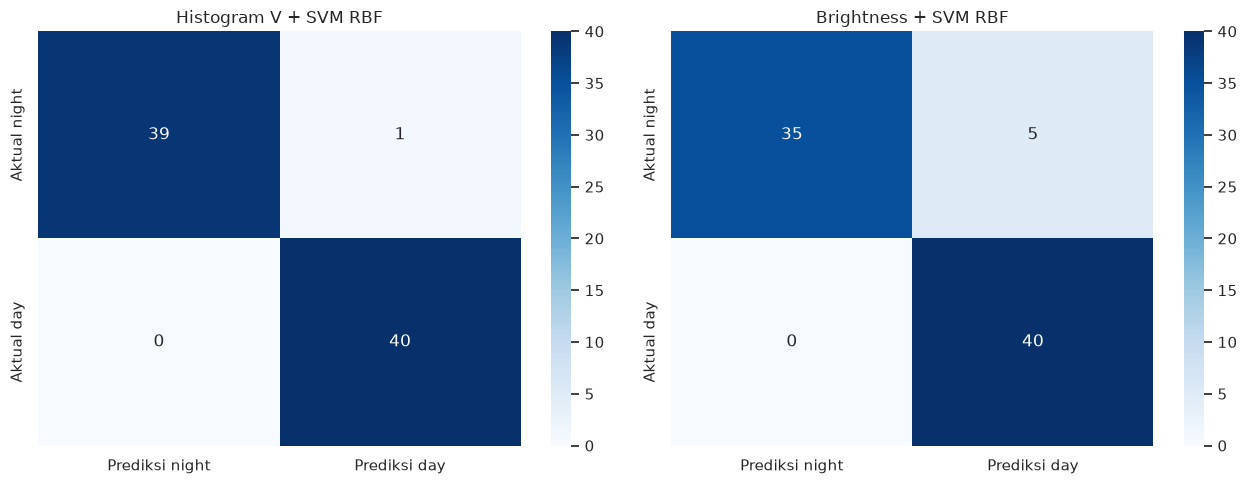

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, pred, title in [
    (axes[0], pred_hist, "Histogram V + SVM RBF"),
    (axes[1], pred_bright, "Brightness + SVM RBF"),
]:
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Prediksi night", "Prediksi day"],
        yticklabels=["Aktual night", "Aktual day"],
        ax=ax,
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

## B.6 Analisis dan kesimpulan Bagian B

**Hasil**

| Fitur | Parameter terbaik | CV accuracy | Akurasi train | Akurasi test | Precision day | Recall day | F1 day |
|---|---|---:|---:|---:|---:|---:|---:|
| Histogram V (32 bin) | `C=1`, `gamma=0.1` | **0,9906** | 0,9938 | **0,9875** | 0,9756 | 1,0000 | 0,9877 |
| Rata-rata kecerahan | `C=0.1`, `gamma=0.01` | 0,9156 | 0,9156 | 0,9375 | 0,8889 | 1,0000 | 0,9412 |
| Threshold 120 | `threshold=120` | — | — | 0,8250 | 0,9643 | 0,6750 | 0,7941 |

**Analisis**

- Histogram V memberikan peningkatan besar dibanding rata-rata kecerahan: akurasi test **98,75%** vs **93,75%**, dan CV **99,06%** vs **91,56%**.
- Histogram menangkap **distribusi** piksel pada berbagai tingkat kecerahan, bukan hanya nilai rata-rata. Dua gambar dengan rata-rata sama bisa memiliki histogram berbeda, misalnya gambar malam dengan lampu terang vs gambar siang yang mendung.
- SVM RBF dengan `C=1` dan `gamma=0.1` menemukan batas keputusan yang sesuai untuk fitur histogram 32 dimensi.
- Hanya ada **1 kesalahan** pada data uji 80 gambar: satu gambar malam diprediksi siang. Tidak ada gambar siang yang diprediksi malam.
- Threshold 120 hanya mencapai 82,50% pada split 80:20, jauh di bawah SVM histogram.

**Keterbatasan**

- Data uji hanya 80 gambar; satu kesalahan sudah mengubah akurasi 1,25 poin persentase.
- Histogram V mengabaikan informasi spasial dan warna hue/saturation.
- Dataset berasal dari kondisi dan lokasi tertentu; performa pada dataset lain bisa berbeda.
- Hyperparameter tuning dilakukan pada data latih; hasil test tetap merupakan estimasi, bukan jaminan.

**Kesimpulan Bagian B**

1. Fitur **histogram V 32 bin** lebih baik daripada rata-rata kecerahan untuk klasifikasi siang/malam.
2. SVM RBF dengan `C=1`, `gamma=0.1` mencapai akurasi test **98,75%** dan CV **99,06%**.
3. Threshold sederhana tidak cukup kuat dibanding SVM dengan fitur histogram.
4. Representasi fitur yang lebih kaya memberikan dampak lebih besar daripada sekadar mengganti classifier.

# Kesimpulan Keseluruhan

1. Pada data suara, **RBF adalah kernel terbaik** untuk split 70:30 (98,32%) dan 80:20 (98,26%), diikuti linear, lalu polynomial.
2. Standardisasi fitur sangat penting; tanpa scaling, akurasi RBF turun menjadi sekitar 69%.
3. Pada citra siang/malam, **histogram V + SVM RBF** mencapai akurasi test **98,75%**, lebih baik daripada rata-rata kecerahan (93,75%) dan threshold 120 (82,50%).
4. Pemilihan fitur dan preprocessing sama pentingnya dengan pemilihan model dan hyperparameter.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS11 – Klasifikasi 2, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2
- `scikit-learn` – Support Vector Machines. https://scikit-learn.org/stable/modules/svm.html
- `scikit-learn` – GridSearchCV. https://scikit-learn.org/stable/modules/grid_search.html
- OpenCV – Histograms. https://docs.opencv.org/4.x/d1/db7/tutorial_py_histogram_begins.html
- Dataset Voice Gender dan Day/Night Image Classifier dari modul praktikum.